Clinical Note Routing: Leakage-Free, Explainable Specialty Classification of Medical Transcriptions

MAAI 902 Natural Language Processing & LLMs · Assessment Task 2: NLP Solution Design ·

Student name: Nourhanne Abdelaziz

Student Numer: 1113173

Part II

# Clinical Note Routing: specialty classification of medical transcriptions
**MAAI 902 – NLP & LLMs · Task 2 (NLP Solution Design) · working prototype**

This notebook walks through the whole pipeline end to end:

1. Load the data and audit it for leakage
2. Build a clean, de-duplicated, multi-label dataset
3. Explore it (class balance, note length, label overlap)
4. Train and compare classical models with leakage-free 5-fold cross-validation
5. Analyse errors, calibration and the human-review trade-off
6. Explain predictions
7. Show how evaluation protocol changes the headline score (ablation)
8. Fine-tune a clinical transformer and run clinical NER (**GPU / Colab cells**)
9. Use the model: route a new note

Every step calls the commented modules in `src/`, so the notebook and the scripts always agree.

### Colab setup
In Colab, run the next cell first. It asks you to upload `clinical-note-routing.zip` (the whole repository), unzips it and moves into the `notebooks` folder. Outside Colab it does nothing.

In [1]:
import os, glob, zipfile
try:
    import google.colab  # noqa: F401  (only exists inside Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    found = glob.glob("/content/**/src/config.py", recursive=True)
    if not found:
        from google.colab import files
        print("Upload clinical-note-routing.zip (the whole repository)")
        uploaded = files.upload()
        for name in uploaded:                      # works even if Colab renamed it, e.g. '... (1).zip'
            if name.endswith(".zip"):
                zipfile.ZipFile(name).extractall("/content")
        found = glob.glob("/content/**/src/config.py", recursive=True)
    if not found:
        raise FileNotFoundError("src/config.py not found: upload clinical-note-routing.zip, not a single file")
    os.chdir(os.path.join(os.path.dirname(os.path.dirname(found[0])), "notebooks"))
print("Project code found:", os.path.exists("../src/config.py"))

Project code found: True


In [2]:
import json, sys
sys.path.insert(0, "../src")   # make the project modules importable
import numpy as np, pandas as pd
import config as C
from data_prep import load_raw, build_dataset, to_matrix, iterative_stratified_folds
pd.set_option("display.max_colwidth", 80)

## 1. Load the raw data and audit it

In [3]:
raw = load_raw()
print(raw.shape)
raw[["medical_specialty", "description", "keywords"]].head(4)

(3813, 7)


,medical_specialty,description,keywords
0,Allergy / Immunology,A 23-year-old white female presents with complaint of allergies.,"allergy / immunology, allergic rhinitis, allergies, asthma, nasal sprays, rh..."
1,Bariatrics,Consult for laparoscopic gastric bypass.,"bariatrics, laparoscopic gastric bypass, weight loss programs, gastric bypas..."
2,Bariatrics,Consult for laparoscopic gastric bypass.,"bariatrics, laparoscopic gastric bypass, heart attacks, body weight, pulmona..."
3,Cardiovascular / Pulmonary,2-D M-Mode. Doppler.,"cardiovascular / pulmonary, 2-d m-mode, doppler, aortic valve, atrial enlarg..."


Two problems show up immediately:

* **`keywords` leaks the label.** It begins with the specialty name in every row, so it must never be a model input.
* **The same note is filed several times.** MTSamples cross-lists a note under every specialty it touches, so rows ≠ notes.

In [4]:
kw_leak = raw.apply(lambda r: str(r.keywords).strip().lower().startswith(r.medical_specialty.lower()), axis=1).mean()
print(f"keywords starts with the label in {kw_leak:.0%} of rows")
print("unique transcriptions:", raw.transcription.str.strip().nunique(), "of", len(raw), "rows")

keywords starts with the label in 100% of rows
unique transcriptions: 1823 of 3813 rows


## 2. Build the clean multi-label dataset
`build_dataset` de-duplicates on cleaned text, merges each note's labels into a set, removes the 7 document-type labels (e.g. *Discharge Summary*, which is a format, not a specialty), drops specialties with fewer than 15 unique notes and notes shorter than 20 words. Folds are then assigned with **iterative stratification** so every specialty is spread across the 5 folds.

In [5]:
notes, stats = build_dataset(raw)
labels = stats["final_labels"]
Y = to_matrix(notes, labels)
notes["fold"] = iterative_stratified_folds(Y, C.N_FOLDS, C.SEED)
{k: stats[k] for k in ["raw_rows", "unique_notes", "notes_with_multiple_labels", "mean_labels_per_note_raw",
                        "final_notes", "n_final_labels", "mean_labels_per_note_final", "words_median", "words_p90"]}

{'raw_rows': 3813,
 'unique_notes': 1821,
 'notes_with_multiple_labels': 1650,
 'mean_labels_per_note_raw': np.float64(2.09),
 'final_notes': 1751,
 'n_final_labels': 24,
 'mean_labels_per_note_final': np.float64(1.82),
 'words_median': 356,
 'words_p90': 765}

In [6]:
notes[["labels", "n_words", "fold"]].head()

,labels,n_words,fold
0,"[Gastroenterology, Surgery]",252,4
1,"[Obstetrics / Gynecology, Surgery, Urology]",1127,3
2,"[Cardiovascular / Pulmonary, Radiology]",241,0
3,"[Cardiovascular / Pulmonary, Radiology]",112,3
4,"[Cardiovascular / Pulmonary, Radiology]",77,1


## 3. Exploratory analysis

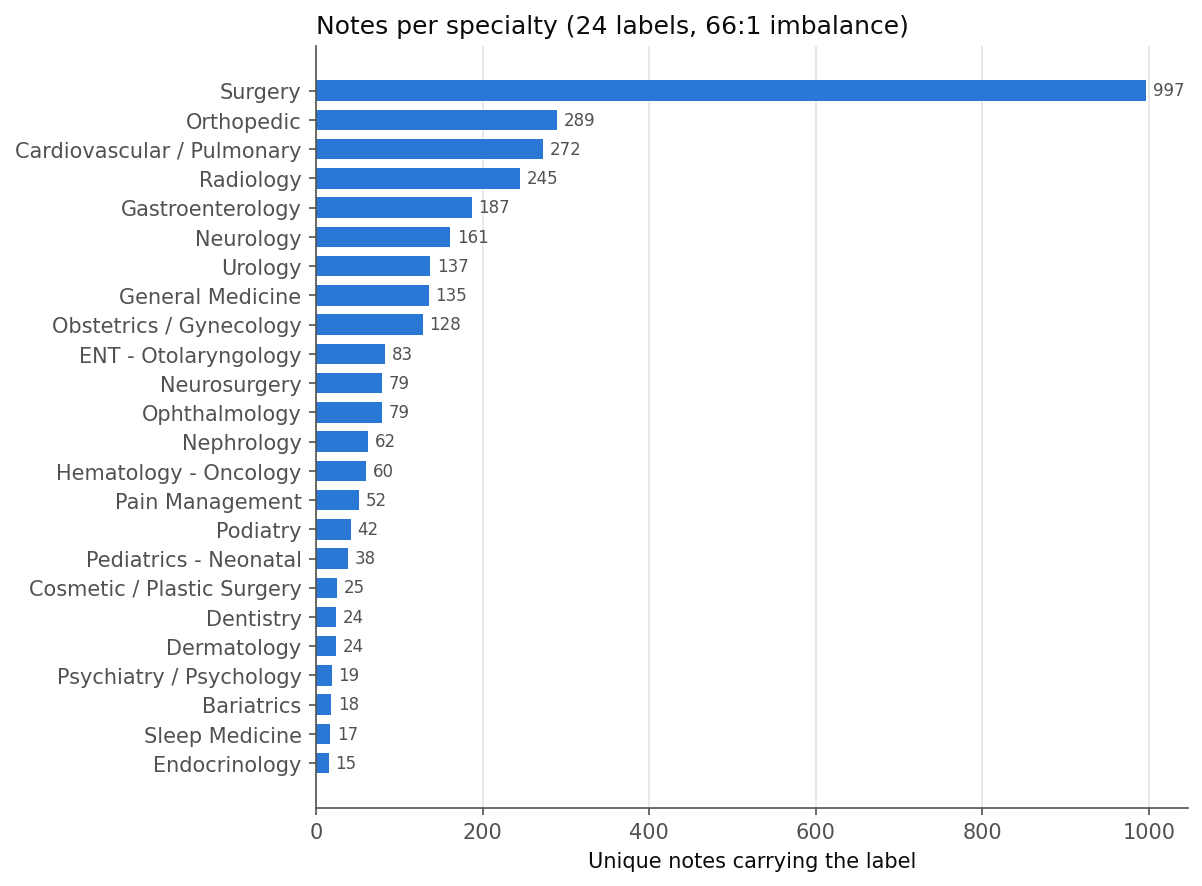

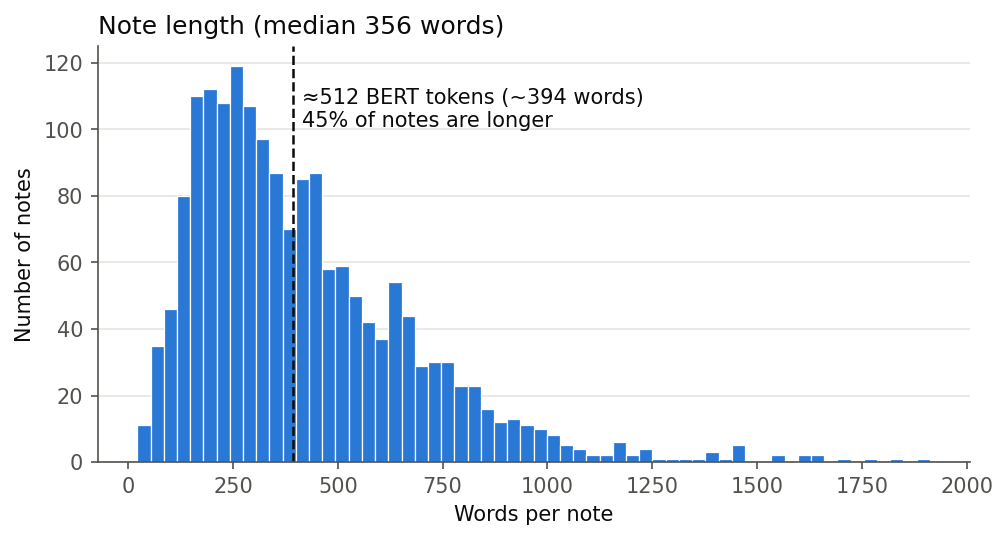

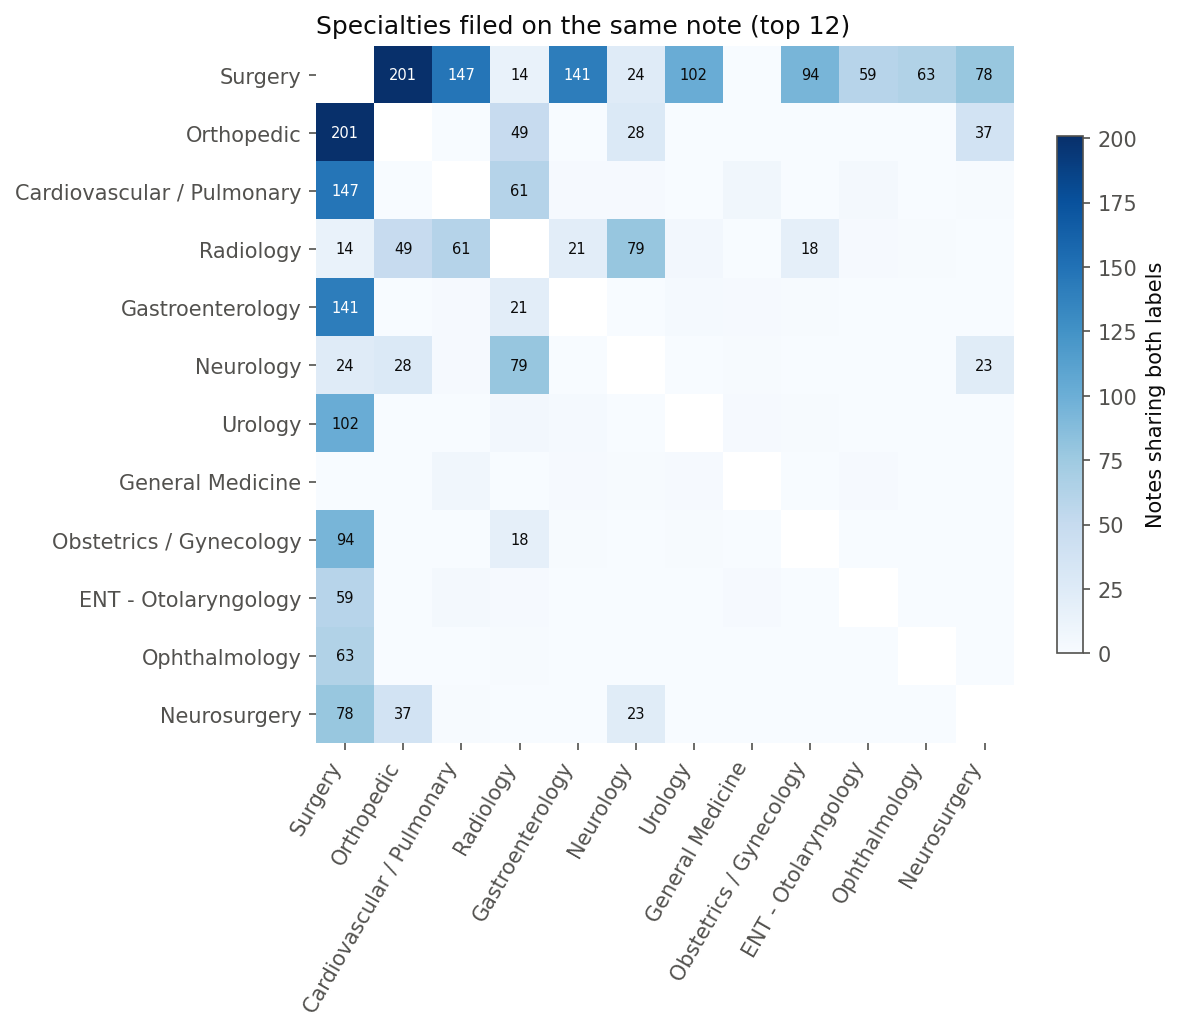

In [7]:
from eda import fig_label_counts, fig_note_length, fig_cooccurrence
from IPython.display import Image, display
fig_label_counts(raw, notes, labels); fig_note_length(notes); fig_cooccurrence(notes, labels)
for f in ["fig1_label_counts", "fig2_note_length", "fig3_cooccurrence"]:
    display(Image(f"../results/figures/{f}.png"))

* Surgery is on 997 notes, Endocrinology on 15: a **66:1 imbalance**, so macro-F1 (every specialty counts equally) is the primary metric.
* **45% of notes exceed ~512 BERT tokens**: a 512-token transformer would silently truncate them, so the transformer script chunks long notes.
* Labels overlap heavily (Surgery with Orthopedic on 201 notes), confirming this is a **multi-label** problem.

## 4. Models and cross-validation
All models use the same folds. Inside each training fold, 15% is held out to tune one global probability threshold; a note receives every specialty above it, and always its top-1. The logistic-regression grid (C × n-gram range) was tuned with the same CV in `train_baseline.py`.

In [8]:
pd.DataFrame(json.load(open("../results/tuning_results.json"))).sort_values("macro_f1", ascending=False).head(6)

,ngram,C,macro_f1,micro_f1,top1_accuracy,secs
4,1-1,64.0,0.809,0.892,0.934,9.8
3,1-1,32.0,0.805,0.889,0.932,9.8
2,1-1,16.0,0.803,0.889,0.932,8.9
1,1-1,4.0,0.791,0.881,0.921,8.4
7,1-2,16.0,0.787,0.886,0.925,18.2
9,1-2,64.0,0.786,0.888,0.929,19.6


In [9]:
from train_baseline import run_cv
rows, oof = [], {}
for disp, name, kw in [("Prior (always Surgery)", "Prior", {}), ("TF-IDF + Naive Bayes", "NB", {}),
                       ("TF-IDF + Linear SVM", "SVM", {}), ("TF-IDF + LR (tuned)", "LR", {"C_lr": 64.0, "ngram": (1, 1)})]:
    res, S, P = run_cv(name, notes, Y, **kw)
    oof[name] = (S, P)
    rows.append({"model": disp, **{m: f"{v[0]:.3f} ± {v[1]:.3f}" for m, v in res.items()}})
pd.DataFrame(rows).set_index("model")

,macro_f1,micro_f1,samples_f1,top1_accuracy
model,,,,
Prior (always Surgery),0.030 ± 0.000,0.404 ± 0.001,0.374 ± 0.003,0.569 ± 0.004
TF-IDF + Naive Bayes,0.545 ± 0.025,0.830 ± 0.013,0.789 ± 0.016,0.870 ± 0.018
TF-IDF + Linear SVM,0.780 ± 0.035,0.886 ± 0.002,0.865 ± 0.005,0.925 ± 0.009
TF-IDF + LR (tuned),0.809 ± 0.033,0.892 ± 0.006,0.876 ± 0.010,0.934 ± 0.011


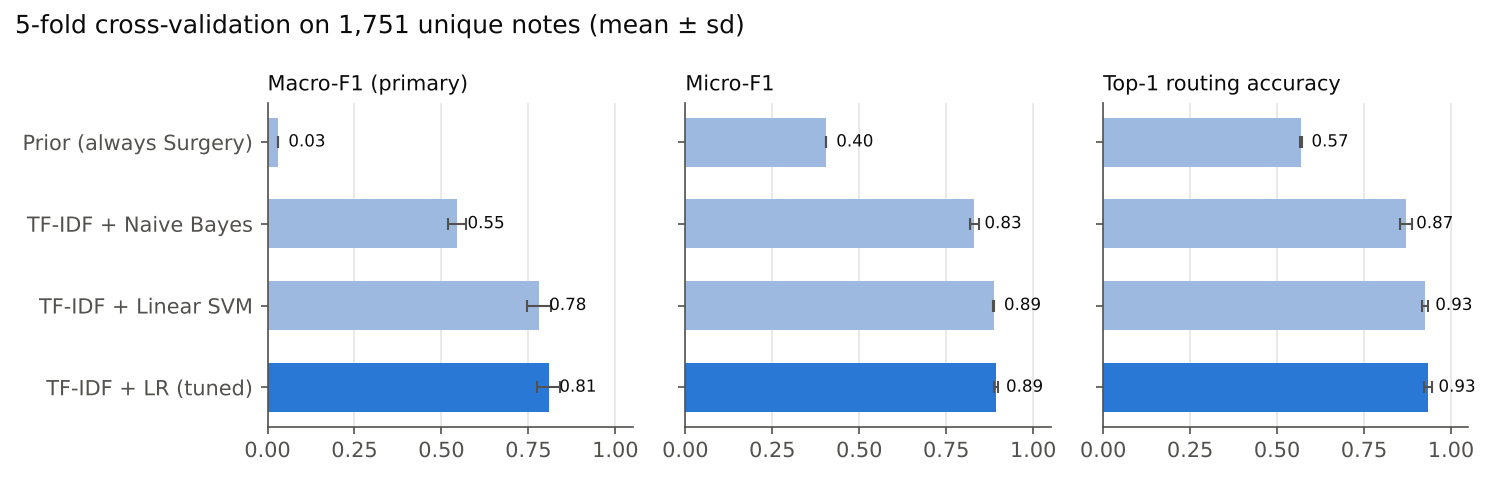

In [10]:
display(Image("../results/figures/fig4_model_comparison.png"))

## 5. Error analysis, calibration and human review

In [11]:
from sklearn.metrics import f1_score
S, P = oof["LR"]
per_label = pd.DataFrame({"F1": f1_score(Y, P, average=None).round(3), "notes": Y.sum(0)}, index=labels)
per_label.sort_values("F1").head(6)

,F1,notes
Pediatrics - Neonatal,0.508,38
Hematology - Oncology,0.569,60
Dermatology,0.629,24
General Medicine,0.653,135
Cosmetic / Plastic Surgery,0.682,25
Endocrinology,0.720,15


Top-1 expected calibration error: 0.039
review threshold 0.5: auto-route 92.6% of notes, top-1 accuracy 95.6%
review threshold 0.7: auto-route 87.5% of notes, top-1 accuracy 96.7%
review threshold 0.9: auto-route 79.0% of notes, top-1 accuracy 98.6%


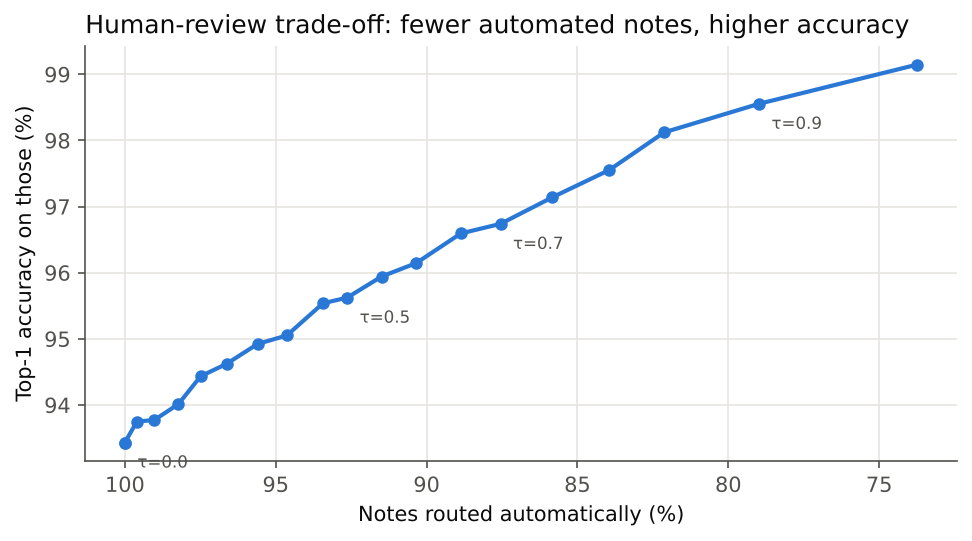

In [12]:
from train_baseline import expected_calibration_error
conf = S.max(1); correct = Y[np.arange(len(Y)), S.argmax(1)].astype(float)
print(f"Top-1 expected calibration error: {expected_calibration_error(conf, correct):.3f}")
for tau in [0.5, 0.7, 0.9]:
    keep = conf >= tau
    print(f"review threshold {tau:.1f}: auto-route {keep.mean():.1%} of notes, top-1 accuracy {correct[keep].mean():.1%}")
display(Image("../results/figures/fig6_review_tradeoff.png"))

Confidence is well calibrated (ECE ≈ 0.04), so the threshold is meaningful: at τ = 0.7 the system routes ~88% of notes automatically at ~97% top-1 accuracy and sends the uncertain ~12% to a person.

The weakest specialties (Pediatrics, Hematology–Oncology, Dermatology, General Medicine) are defined by *who* the patient is or by broad scope rather than by distinctive procedure vocabulary.

## 6. Explainability: what the model relies on

In [13]:
from predict import load       # loads the saved model, or retrains it if scikit-learn versions differ
bundle = load()
vocab = bundle["model"].named_steps["tfidf"].get_feature_names_out()
top_terms = {lab: ", ".join(vocab[np.argsort(-est.coef_[0])[:6]])
             for lab, est in zip(bundle["labels"], bundle["model"].named_steps["clf"].estimators_)}
pd.Series(top_terms, name="highest-weight words").to_frame().head(12)

,highest-weight words
Bariatrics,"gastric, obesity, bypass, morbid, weight, bmi"
Cardiovascular / Pulmonary,"chest, lung, bronchoscopy, pleural, pulmonary, heart"
Cosmetic / Plastic Surgery,"breast, fold, wounds, liposuction, breasts, belly"
Dentistry,"tooth, dental, mandible, teeth, pack, throat"
Dermatology,"punch, buttock, biopsy, areas, skin, lesion"
ENT - Otolaryngology,"ear, nasal, nasopharynx, cartilage, tympanic, tonsil"
Endocrinology,"thyroid, gland, insulin, strap, lantus, glucoses"
Gastroenterology,"abdominal, esophagus, abdomen, colon, gallbladder, stomach"
General Medicine,"discharge, admission, tms, negative, emergency, hypertension"
Hematology - Oncology,"excision, cancer, breast, chemotherapy, mesothelioma, radiation"


The words are clinically sensible (Ophthalmology → *eye, lid, lens*; Urology → *bladder, prostate*), which is a basic sanity check that the model learned medicine rather than artefacts. Note that **Radiology** relies on report-structure words (*exam, images, impression, technique*): it is partly a document style, which is why it co-occurs with many organ specialties.

## 7. Ablation: the evaluation protocol drives the headline number
Same model (TF-IDF + LR), different protocols (`src/leakage_experiments.py`).

In [14]:
pd.DataFrame(json.load(open("../results/leakage_experiments.json"))).T

,accuracy,weighted_f1,macro_f1,micro_f1,samples_f1,top1_accuracy
"E0 random split, no oversampling",0.104,0.099,0.057,NaN,NaN,NaN
E1 oversample before split,0.807,0.783,0.783,NaN,NaN,NaN
E2 oversample after split,0.104,0.102,0.071,NaN,NaN,NaN
E3 + keywords column,0.722,0.728,0.529,NaN,NaN,NaN
E4 grouped split (no shared text),0.444,0.403,0.202,NaN,NaN,NaN
"E5 multi-label, all 39 labels",NaN,NaN,0.695,0.863,0.857,0.946
"E6 multi-label, 24 cleaned labels",NaN,NaN,0.809,0.892,0.876,0.934


* **E0:** with one-row-one-label and a random split, accuracy is only 0.10. The test note's *text* is usually in training under a *different, also-correct* label, so the model's right answer is scored wrong.
* **E1:** oversampling **before** the split copies test notes into training, and accuracy jumps to 0.81. This is pure leakage.
* **E3:** adding the `keywords` column lifts E2 from 0.10 to 0.72 for the same reason.
* **E5 → E6:** the multi-label framing removes the contradiction. The taxonomy fix (dropping document types and very rare labels) raises macro-F1 from 0.70 to 0.81.

This explains why published MTSamples scores range from ~0.28 to ~0.99.

## 8. Transformer fine-tuning and clinical NER (run on GPU / Colab)
These cells need internet access to Hugging Face / scispaCy and a GPU. They are **not executed in this copy of the notebook**. Run them in Colab (Runtime → GPU) and paste the results into the report's results table.

In [15]:
# Runtime -> Change runtime type -> T4 GPU, then run this cell
!pip install -q transformers accelerate
!python ../src/data_prep.py      # writes data/notes_multilabel.pkl, which the transformer script reads
# Bio_ClinicalBERT (512 tokens, chunked), all 5 folds, about 45 min on a T4
!python ../src/train_transformer.py --model emilyalsentzer/Bio_ClinicalBERT --folds 0 1 2 3 4
# Long-context alternative (4,096 tokens)
# !python ../src/train_transformer.py --model yikuan8/Clinical-Longformer --max-len 4096 --batch 2 --accum 8

{
  "raw_rows": 3813,
  "raw_labels": 39,
  "keywords_start_with_label_pct": 100.0,
  "unique_notes": 1821,
  "duplicate_rows_removed": 1992,
  "notes_with_multiple_labels": 1650,
  "mean_labels_per_note_raw": 2.09,
  "document_type_labels_removed": [
    "Consult - History and Phy.",
    "Discharge Summary",
    "Emergency Room Reports",
    "IME-QME-Work Comp etc.",
    "Letters",
    "Office Notes",
    "SOAP / Chart / Progress Notes"
  ],
  "rare_labels_removed": [
    "Allergy / Immunology",
    "Chiropractic",
    "Diets and Nutritions",
    "Hospice - Palliative Care",
    "Lab Medicine - Pathology",
    "Physical Medicine - Rehab",
    "Rheumatology",
    "Speech - Language"
  ],
  "notes_dropped_no_specialty": 47,
  "notes_dropped_too_short": 23,
  "final_notes": 1751,
  "final_labels": [
    "Bariatrics",
    "Cardiovascular / Pulmonary",
    "Cosmetic / Plastic Surgery",
    "Dentistry",
    "Dermatology",
    "ENT - Otolaryngology",
    "Endocrinology",
    "Gastroenterolog

In [17]:
!pip install -q --no-deps https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_ner_bc5cdr_md-0.5.4.tar.gz
!pip install -q transformers
from collections import Counter

text = raw["transcription"].iloc[0]          # original text: NER needs punctuation and sentences
try:                                          # 1) scispaCy
    import spacy
    nlp = spacy.load("en_ner_bc5cdr_md")
    ents = [(e.label_, e.text.lower()) for e in nlp(text).ents]
    print("Back-end: scispaCy en_ner_bc5cdr_md")
except Exception as err:                      # 2) Hugging Face fallback
    print("scispaCy unavailable:", type(err).__name__, "-> using Hugging Face model")
    from transformers import pipeline
    ner = pipeline("token-classification", model="d4data/biomedical-ner-all", aggregation_strategy="simple")
    MAP = {"Disease_disorder": "DISEASE", "Sign_symptom": "DISEASE", "Medication": "CHEMICAL",
           "Diagnostic_procedure": "PROCEDURE", "Therapeutic_procedure": "PROCEDURE"}
    words = text.split()
    ents = [(MAP[e["entity_group"]], e["word"].lower())
            for i in range(0, len(words), 180)
            for e in ner(" ".join(words[i:i + 180]))
            if e["entity_group"] in MAP and e["score"] >= 0.5]

for label in ["DISEASE", "CHEMICAL", "PROCEDURE"]:
    print(label, Counter(w for l, w in ents if l == label).most_common(10))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/spacy/util.py:971: UserWarning: [W095] Model 'en_ner_bc5cdr_md' (0.5.4) was trained with spaCy v3.7.4 and may not be 100% compatible with the current version (3.8.16). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


scispaCy unavailable: ConfigValidationError -> using Hugging Face model


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/5.00k [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

DISEASE [('all', 2), ('##ergies', 1), ('asthma', 1), ('erythematous', 1), ('er', 1), ('##ythematous', 1), ('aden', 1)]
CHEMICAL [('all', 2), ('medication', 1), ('or', 1), ('##tho tri - cyclen', 1), ('lo', 1), ('##rata', 1), ('prescription', 1), ('nas', 1), ('##one', 1)]
PROCEDURE [('vitals', 1), ('weight', 1), ('blood pressure', 1), ('t', 1)]


## 9. Use the model: route a new note

In [18]:
from predict import route
note = '''HISTORY: 67-year-old male with progressive shortness of breath and chest tightness on exertion.
ECHOCARDIOGRAM: ejection fraction 35%, moderate mitral regurgitation, left ventricular hypertrophy.
PLAN: start beta blocker, cardiology follow-up, consider cardiac catheterization.'''
r = route(note)
print("Assigned:", r["assigned"], "| top:", r["top"], f"({r['confidence']:.0%})", "| decision:", r["decision"])
print("Evidence:", [w for w, _ in r["evidence"]])

Assigned: ['Cardiovascular / Pulmonary'] | top: Cardiovascular / Pulmonary (99%) | decision: auto-route
Evidence: ['chest', 'ventricular', 'cardiac', 'echocardiogram', 'mitral', 'breath', 'exertion', 'regurgitation']


The same model runs in the browser (`demo/index.html`) and in a Gradio app (`python src/app.py`).

*Research prototype: not for clinical use.*

In [20]:
!pip install -q gradio
from app import demo
demo.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e8f2fa533d7822d0fe.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


GPU

In [21]:
!nvidia-smi

Wed Oct 28 15:33:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P0             26W /   70W |     701MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [22]:
import glob
p = glob.glob("/content/**/src/train_transformer.py", recursive=True)[0]
s = open(p).read()
s = s.replace(
    "warmup_ratio=0.1,",
    "warmup_steps=int(0.1 * (-(-len(ds_fit) // (args.batch * args.accum))) * args.epochs),",
)
open(p, "w").write(s)
print("Patched:", "warmup_ratio" not in s)

SRC = p.rsplit("/", 1)[0]
!python {SRC}/train_transformer.py --model emilyalsentzer/Bio_ClinicalBERT --folds 0

Patched: False
Loading weights: 100% 199/199 [00:00<00:00, 11917.68it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- M